Author:  José Luis Durán

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

El dataset se encuentra en la carpeta `datasets/` de este repositorio (`datasets/titanic.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Carga del dataset desde la carpeta local del repositorio
df = pd.read_csv("datasets/titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [2]:
# Inspección del dataset: dimensiones, tipos de datos, valores faltantes y estadísticas descriptivas.
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas\n")

print("Tipos de datos:")
print(df.dtypes, "\n")

# Se muestran solo las columnas que tienen al menos un valor faltante
print("Valores faltantes por columna:")
faltantes = df.isna().sum()
print(faltantes[faltantes > 0], "\n")

print("Estadísticas descriptivas (columnas numéricas):")
display(df.describe().round(2))

Dimensiones: 891 filas x 12 columnas

Tipos de datos:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object 

Valores faltantes por columna:
Age         177
Cabin       687
Embarked      2
dtype: int64 

Estadísticas descriptivas (columnas numéricas):


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

**Respuesta:**

- **Estructura:** el dataset tiene 891 filas que corresponden a pasajeros y 12 columnas, 5 de esas tienen tipo de dato entero (`PassengerId`, `Survived`, `Pclass`, `SibSp`, `Parch`), 2 tipo de dato decimal (`Age`, `Fare`) y 5 de texto (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`).
- **Valores faltantes:** tres columnas están incompletas: `Cabin` con 687 filas faltantes (aprox 77.1 %), `Age` con 177 filas faltantes (aprox 19.9 %) y `Embarked` con 2 faltantes (aprox 0.2 %). El resto de las columnas están completas.
- **Observación de las estadísticas:** como `Survived` es binaria (0/1), su media (0.38) corresponde a la tasa global de supervivencia. Solo el 38.4 % de los pasajeros del dataset sobrevivió. Además, `Fare` presenta una fuerte asimetría a la derecha: su media (32.20) es más del doble de su mediana (14.45) y su máximo (512.33) está muy por encima del percentil 75 (31.00).
- **Preprocesamiento:** no se requiere para las dos hipótesis. Las variables que intervienen (`Sex`, `Pclass` y `Survived`) no tienen valores faltantes y ya están en un formato que se puede utilizar. Tratar los datos faltantes de `Age`, `Cabin` y `Embarked` solo sería necesario si se fueran a utilizar esas columnas.

### Perfil del dataset con fg-data-profiling

Como complemento a la inspección manual, se genera un reporte automático con `fg-data-profiling` (ydata-profiling ya está en desuso y pedía hacer downgrade de otras librerías). 

El reporte se exporta como archivo HTML en `reports/titanic_profile.html`.

In [3]:
# Generación de un reporte exploratorio automático con fg-data-profiling.
# Complementa la inspección manual realizada en la sección anterior.
from pathlib import Path
from data_profiling import ProfileReport

# Descripción de cada variable, visible dentro del reporte
descripciones = {
    "PassengerId": "Identificador único del pasajero",
    "Survived": "Supervivencia (0 = no, 1 = sí)",
    "Pclass": "Clase del boleto (1 = primera, 2 = segunda, 3 = tercera)",
    "Name": "Nombre del pasajero",
    "Sex": "Sexo del pasajero",
    "Age": "Edad del pasajero (años)",
    "SibSp": "Número de hermanos o cónyuges a bordo",
    "Parch": "Número de padres o hijos a bordo",
    "Ticket": "Número de boleto",
    "Fare": "Tarifa pagada",
    "Cabin": "Número de camarote",
    "Embarked": "Puerto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton)",
}

perfil = ProfileReport(
    df,
    title="Perfil exploratorio del dataset Titanic",
    variables={"descriptions": descripciones},
    progress_bar=False,
)

# El reporte se guarda como HTML independiente para no aumentar el tamaño del notebook
Path("reports").mkdir(exist_ok=True)
perfil.to_file("reports/titanic_profile.html")
print("Reporte generado en: reports/titanic_profile.html")

# fg-data-profiling cambia el backend de matplotlib a "agg" durante la generación del
# reporte; se reactiva el backend inline para que las celdas siguientes muestren gráficos
%matplotlib inline

100%|██████████| 12/12 [00:00<00:00, 33.40it/s]


Reporte generado en: reports/titanic_profile.html


**Hallazgos del perfil relacionados con este análisis:**

- **Valores faltantes:** el reporte confirma lo obtenido en la inspección manual: `Cabin` con 687 faltantes (77.1 %) y `Age` con 177 (19.9 %). Los 2 faltantes de `Embarked` aparecen en la sección *Missing values*.
- **Correlación con la supervivencia:** el reporte genera una alerta de correlación alta entre `Sex` y `Survived`, lo que anticipa el resultado de la Hipótesis 1. La relación entre `Pclass` y `Survived` se observa en la matriz de correlaciones (sección *Correlations*), aunque no alcanza el umbral de alerta.
- **Tarifa:** `Fare` tiene 15 valores iguales a cero (1.7 %), lo que explica el mínimo de 0 en las estadísticas descriptivas; su histograma muestra la asimetría a la derecha descrita en las notas de inspección.
- **Composición familiar:** `SibSp` tiene 68.2 % de ceros y `Parch` 76.1 %; la mayoría de los pasajeros viajaba sin hermanos, cónyuge, padres ni hijos a bordo.
- **Identificadores:** `PassengerId` y `Name` tienen valores únicos en todas las filas; son identificadores y no aportan información para las hipótesis.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

,Pasajeros,Sobrevivientes,Tasa de supervivencia (%)
Sexo,,,
Mujeres,314,233,74.20
Hombres,577,109,18.89


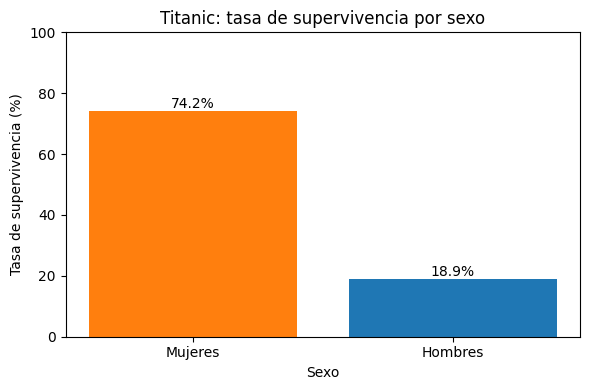

In [4]:
# Cálculo de la tasa de supervivencia por sexo y visualización de la comparación.
resumen_sexo = df.groupby("Sex")["Survived"].agg(["count", "sum", "mean"])
resumen_sexo.columns = ["Pasajeros", "Sobrevivientes", "Tasa"]
# La media de una variable binaria (0/1) equivale a la proporción de sobrevivientes
resumen_sexo["Tasa de supervivencia (%)"] = (resumen_sexo["Tasa"] * 100).round(2)
resumen_sexo.index = resumen_sexo.index.map({"female": "Mujeres", "male": "Hombres"})
resumen_sexo = resumen_sexo.rename_axis("Sexo")
display(resumen_sexo.drop(columns="Tasa"))

# Gráfico de barras con el valor de cada tasa sobre la barra
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(resumen_sexo.index,
                resumen_sexo["Tasa de supervivencia (%)"],
                color=["tab:orange", "tab:blue"])
ax.bar_label(barras, fmt="%.1f%%")
ax.set_title("Titanic: tasa de supervivencia por sexo")
ax.set_xlabel("Sexo")
ax.set_ylabel("Tasa de supervivencia (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

**Respuesta:**

Los datos muestran que las mujeres tuvieron una tasa de supervivencia mucho mayor en comparación con los hombres. De 314 pasajeros registrados como mujeres sobrevivieron 233 (74.20%), mientras que de 577 pasajeros registrados como hombres sobrevivieron 109 (18.89%). La tasa de supervivencia de las mujeres es aproximadamente 3.9 veces la de los hombres, una diferencia de 55.3 puntos porcentuales. Esto demuestra que, pese a que había más pasajeros hombres, la diferencia de supervivencia se hace evidente al comparar porcentajes en lugar de números absolutos.

En este caso el dataset respalda la hipótesis 1. El resultado es coherente con el protocolo de evacuación clásico de navíos de "mujeres y niños primero".

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

,Pasajeros,Sobrevivientes,Tasa de supervivencia (%)
Clase,,,
1.ª clase,216,136,62.96
2.ª clase,184,87,47.28
3.ª clase,491,119,24.24


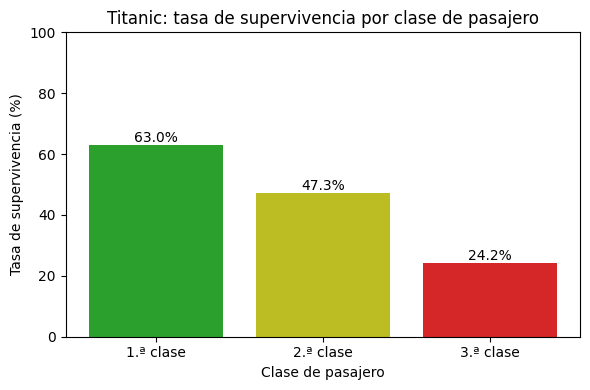

In [5]:
# Cálculo de la tasa de supervivencia por clase de pasajero y visualización de la comparación.
resumen_clase = df.groupby("Pclass")["Survived"].agg(["count", "sum", "mean"])
resumen_clase.columns = ["Pasajeros", "Sobrevivientes", "Tasa"]
resumen_clase["Tasa de supervivencia (%)"] = (resumen_clase["Tasa"] * 100).round(2)
resumen_clase.index = resumen_clase.index.map({1: "1.ª clase", 2: "2.ª clase", 3: "3.ª clase"})
resumen_clase = resumen_clase.rename_axis("Clase")
display(resumen_clase.drop(columns="Tasa"))

# Gráfico de barras con el valor de cada tasa sobre la barra
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(resumen_clase.index,
                resumen_clase["Tasa de supervivencia (%)"],
                color=["tab:green", "tab:olive", "tab:red"])
ax.bar_label(barras, fmt="%.1f%%")
ax.set_title("Titanic: tasa de supervivencia por clase de pasajero")
ax.set_xlabel("Clase de pasajero")
ax.set_ylabel("Tasa de supervivencia (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

**Respuesta:**

El dataset muestra que los pasajeros de primera clase tuvieron una mayor tasa de supervivencia: en total sobrevivieron 136 de 216 (62.96%), por su lado los de segunda clase sobrevivieron 87 de 184 (47.28%) y los de tercera clase tuvieron el porcentaje más bajo al sobrevivir solo 119 de 491 (24.24%). El % de supervivencia disminuye de forma clara al bajar de clase. La tasa de supervivencia de primera clase es aproximadamente 2.6 veces la de tercera clase. En números absolutos la diferencia es mucho menor (136 frente a 119 sobrevivientes), porque en tercera clase viajaban más del doble de pasajeros.

Los datos evaluados respaldan la hipótesis 2. Una posible razón para esto es que los pasajeros de primera clase tenían mejores camarotes, más cerca de la cubierta y de los botes salvavidas, o más cerca del personal del barco que les podía ayudar a evacuar.

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>